# MSBD 566 — Assignment 2: Validation, Tuning and Honest Evaluation

**Student:** Francena Scott  
**Course:** MSBD 566 Predictive Modeling and Analytics — Meharry Medical College, School of Applied Computational Sciences  
**Date:** November 17, 2026  
**Dataset:** UCI Parkinson's Disease Classification (Sakar et al., 2019; CC BY 4.0) — 756 sustained-vowel recordings from 252 subjects

**Honor statement.** I, Francena Scott, affirm that this notebook is my own work. I wrote the code and the written answers, I can explain every step, and I did not give or receive unauthorized assistance. Every number I quote below was produced by running this notebook, not copied from anywhere else.

**How to read this notebook.** Each of the six parts opens with a markdown heading, then code, then the written answers *directly under* the code that supports them (Q1–Q14). Conventions used throughout: one seed (`random_state=42`) for every splitter, search and model; metrics reported to three decimals; the held-out test set is created in Part 2 and is **not touched again until Part 6**, where it is evaluated exactly once.


### Contents

| Part | Topic | Questions | Points |
|---|---|---|---|
| 1 | Understand the data | Q1–Q2 | 10 |
| 2 | Splitting and leakage | Q3–Q5 | 15 |
| 3 | Leakage inside the pipeline | Q6–Q7 | 10 |
| 4 | Bias, variance and regularization | Q8–Q9 | 15 |
| 5 | Tuning and honest model selection | Q10–Q12 | 25 |
| 6 | Final evaluation and decisions | Q13–Q14 | 15 |
| — | Notebook quality (comments, structure, reproducibility) | — | 10 |


In [1]:
%matplotlib inline

In [2]:
# ---------------------------------------------------------------------------
# Setup.  One seed is reused everywhere so the whole notebook is reproducible;
# nothing below relies on the test set until Part 6.
# ---------------------------------------------------------------------------
import platform
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# HalvingRandomSearchCV still lives behind scikit-learn's "experimental" flag.
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Small, legible figures that keep the notebook file light.
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titlesize": 10, "axes.labelsize": 9})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)

# Relative path first so the notebook still runs if the folder is moved; the
# absolute path is the copy that actually ships with this workspace.
DATA_CANDIDATES = [
    Path("data/rarout/pd_speech_features.csv"),      # run from the repository root
    Path("../data/rarout/pd_speech_features.csv"),   # run from the Assignment 2 folder
    Path.home() / "Downloads" / "pd_speech_features.csv",
]
DATA_PATH = next(p for p in DATA_CANDIDATES if p.exists())

NOTEBOOK_T0 = time.perf_counter()

print("Python      :", platform.python_version())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("data file   :", DATA_PATH)
print("seed        :", RANDOM_STATE)

Python      : 3.12.10
numpy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1
matplotlib  : 3.11.2
data file   : ..\data\rarout\pd_speech_features.csv
seed        : 42


## Part 1. Understand the data

**The prediction task.** Given one sustained-vowel recording, predict whether the speaker has Parkinson's disease (`class` = 1) or is healthy (`class` = 0). Each recording is described by 752 acoustic features (baseline jitter/shimmer, intensity, formants, bandwidths, vocal-fold measures, MFCCs, wavelet and TQWT coefficients).

**Who would use it.** A neurology or speech-language-pathology clinic as a *triage* step: a cheap, non-invasive voice sample that decides who should be referred for a full neurological work-up. It is a screening aid, never a diagnosis on its own.

**Success metric.** Because the classes are imbalanced (about 3:1) and a false negative (missing a person who has Parkinson's) is the costly error, I will judge models primarily by **ROC AUC** (threshold-free, comparable across parts) and, for the final decision, by **sensitivity and specificity at a chosen threshold** plus **average precision** and a **calibration curve**. Accuracy alone is not usable here: a model that says "Parkinson's" to everyone already scores 0.746.

In [3]:
# header=1 is required by this file: row 0 holds feature-group labels, not names.
df = pd.read_csv(DATA_PATH, header=1)

FEATURES = [c for c in df.columns if c not in ("id", "gender", "class")]
X_all = df[FEATURES].to_numpy(dtype=float)
y_all = df["class"].to_numpy(dtype=int)
groups_all = df["id"].to_numpy()

subject_class = df.groupby("id")["class"].first()        # one row per person
recs_per_subject = df.groupby("id").size()
class_counts = df["class"].value_counts().sort_index()
pos_share = float(df["class"].mean())
abs_max = np.abs(X_all).max(axis=0)

# The feature-group labels are in the first line of the file, which header=1 skips.
raw_header = pd.read_csv(DATA_PATH, header=None, nrows=1)
block_labels = [v for v in raw_header.iloc[0] if isinstance(v, str)]

dup_mask = df.duplicated(keep=False)
dup_ids = sorted(df.loc[dup_mask, "id"].unique().tolist())
rec_txt = "; ".join(f"{n} recording(s): {c} subjects"
                    for n, c in recs_per_subject.value_counts().sort_index().items())

audit = pd.DataFrame([
    ("shape (recordings x columns)", f"{df.shape[0]} x {df.shape[1]}"),
    ("subjects -> unit of independence", f"{df['id'].nunique()}"),
    ("recordings per subject", rec_txt),
    ("class 1 (Parkinson's) recordings", f"{class_counts[1]} ({pos_share:.1%})"),
    ("class 0 (healthy) recordings", f"{class_counts[0]} ({1 - pos_share:.1%})"),
    ("subjects with Parkinson's", f"{int((subject_class == 1).sum())} ({(subject_class == 1).mean():.1%})"),
    ("numeric features", f"{len(FEATURES)}"),
    ("missing cells", f"{int(df.isna().sum().sum())}"),
    ("exact duplicate rows", f"{int(dup_mask.sum() // 2)} pair(s), subject id(s) {dup_ids}"),
    ("duplicate on (id + features)", f"{int(df.duplicated(subset=['id'] + FEATURES).sum())}"),
    ("constant features", f"{int((X_all.std(axis=0) == 0).sum())}"),
    ("largest |feature value|", f"{abs_max.max():.2e}"),
    ("features with |value| > 1e8", f"{int((abs_max > 1e8).sum())}"),
    ("gender coding", f"1: {int((df['gender'] == 1).sum())} recordings, 0: {int((df['gender'] == 0).sum())}"),
    ("subjects with mixed class / gender", f"{int((df.groupby('id')['class'].nunique() > 1).sum())} / {int((df.groupby('id')['gender'].nunique() > 1).sum())}"),
    ("feature blocks declared in raw header", f"{len(block_labels)}"),
], columns=["check", "value"])
print(audit.to_string(index=False))

print("\nfeature blocks :", " | ".join(block_labels))
top_scale = pd.Series(abs_max, index=FEATURES).sort_values(ascending=False).head(4)
print("\nfeatures with the widest range (max |value|):")
for name, val in top_scale.items():
    print(f"   {name:<34s} {val:.3e}")
print("\nsubject 37's three rows (the duplicated recording pair):")
print(df.loc[df["id"] == 37, ["id", "gender", "class", "PPE", "DFA"]].to_string())

                                check                         value
         shape (recordings x columns)                     756 x 755
     subjects -> unit of independence                           252
               recordings per subject  3 recording(s): 252 subjects
     class 1 (Parkinson's) recordings                   564 (74.6%)
         class 0 (healthy) recordings                   192 (25.4%)
            subjects with Parkinson's                   188 (74.6%)
                     numeric features                           752
                        missing cells                             0
                 exact duplicate rows 1 pair(s), subject id(s) [37]
         duplicate on (id + features)                             1
                    constant features                             0
              largest |feature value|                      6.21e+10
          features with |value| > 1e8                            12
                        gender coding     1: 390

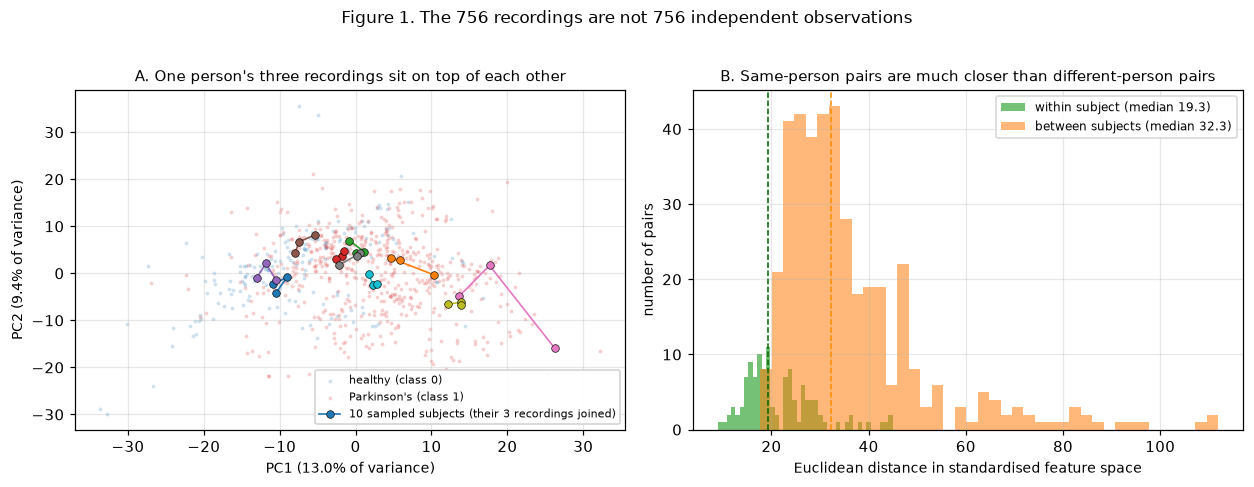

median within-subject distance   : 19.28
median between-subject distance  : 32.33
ratio within / between           : 0.596


In [4]:
# ---------------------------------------------------------------------------
# Figure 1.  Is a recording an independent observation?  Standardise first:
# the features span ~1e10 in magnitude (audit above), so an unscaled PCA would
# be driven by a handful of columns.
# ---------------------------------------------------------------------------
X_std = StandardScaler().fit_transform(X_all)
pca = PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)
Z = pca.fit_transform(X_std)

row_of = {}
for i, s in enumerate(groups_all):
    row_of.setdefault(s, []).append(i)
subjects = np.array(sorted(row_of))
rng = np.random.RandomState(RANDOM_STATE)

# Same space, same question: are the three recordings of one person closer to
# each other than to other people?
within, between = [], []
for s in rng.choice(subjects, 40, replace=False):
    ii = row_of[s]
    for a in range(3):
        for b in range(a + 1, 3):
            within.append(np.linalg.norm(X_std[ii[a]] - X_std[ii[b]]))
for _ in range(400):
    a, b = rng.choice(subjects, 2, replace=False)
    between.append(np.linalg.norm(X_std[row_of[a][0]] - X_std[row_of[b][0]]))

show = []
for cls in (0, 1):
    pool = [s for s in subjects if subject_class.loc[s] == cls]
    show += list(rng.choice(pool, 5, replace=False))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), dpi=110)

ax = axes[0]
for cls, colour, label in [(0, "tab:blue", "healthy (class 0)"),
                           (1, "tab:red", "Parkinson's (class 1)")]:
    m = y_all == cls
    ax.scatter(Z[m, 0], Z[m, 1], s=6, c=colour, alpha=0.22, linewidths=0, label=label)
cmap = plt.get_cmap("tab10")
for i, s in enumerate(show):
    ii = row_of[s]
    ax.plot(Z[ii, 0], Z[ii, 1], "-o", color=cmap(i % 10), ms=5, lw=1.1,
            mec="black", mew=0.4, zorder=3,
            label="10 sampled subjects (their 3 recordings joined)" if i == 0 else None)
ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% of variance)")
ax.set_title("A. One person's three recordings sit on top of each other")
ax.legend(fontsize=7, loc="lower right", framealpha=0.9)

ax = axes[1]
ax.hist(within, bins=40, alpha=0.65, color="tab:green",
        label=f"within subject (median {np.median(within):.1f})")
ax.hist(between, bins=40, alpha=0.55, color="tab:orange",
        label=f"between subjects (median {np.median(between):.1f})")
ax.axvline(np.median(within), color="darkgreen", ls="--", lw=1)
ax.axvline(np.median(between), color="darkorange", ls="--", lw=1)
ax.set_xlabel("Euclidean distance in standardised feature space")
ax.set_ylabel("number of pairs")
ax.set_title("B. Same-person pairs are much closer than different-person pairs")
ax.legend(fontsize=8)

fig.suptitle("Figure 1. The 756 recordings are not 756 independent observations", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

print(f"median within-subject distance   : {np.median(within):.2f}")
print(f"median between-subject distance  : {np.median(between):.2f}")
print(f"ratio within / between           : {np.median(within) / np.median(between):.3f}")

In [5]:
# The baseline every model has to beat: ignore the features, always answer the
# majority class.  Its accuracy looks respectable, which is exactly why
# accuracy is the wrong headline metric for this dataset.
majority_label = int(class_counts.idxmax())
majority_acc = float(class_counts.max() / len(df))
pred_all_majority = np.full_like(y_all, majority_label)
tn, fp, fn, tp = confusion_matrix(y_all, pred_all_majority, labels=[0, 1]).ravel()

print(f"always predict class {majority_label} (Parkinson's)")
print(f"   accuracy                     : {majority_acc:.3f}")
print(f"   sensitivity (PD caught)      : {tp / (tp + fn):.3f}")
print(f"   specificity (healthy cleared): {tn / (tn + fp):.3f}")
print(f"   balanced accuracy            : {0.5 * (tp / (tp + fn) + tn / (tn + fp)):.3f}")
print(f"   ROC AUC                      : {roc_auc_score(y_all, pred_all_majority):.3f}")

always predict class 1 (Parkinson's)
   accuracy                     : 0.746
   sensitivity (PD caught)      : 1.000
   specificity (healthy cleared): 0.000
   balanced accuracy            : 0.500
   ROC AUC                      : 0.500


### Q1. Unit of observation vs unit of independence

The unit of observation is a single sustained-vowel recording: the file has 756 rows and 755 columns (id, gender, 752 acoustic features, class), so one row is one recording. The unit of independence is the subject: those 756 recordings come from 252 people with exactly three recordings each, and the label never varies inside a person (188 subjects with Parkinson's, 64 healthy). Figure 1 shows the three recordings of one person sitting almost on top of each other in standardised feature space - the median within-subject distance is 19.28 against 32.33 between subjects, a ratio of 0.596 - so they behave like near-duplicates rather than three independent draws. That is why every split in this notebook is made at the subject level, and why the honest sample size for any estimate here is 252 people, not 756 recordings.

### Q2. Majority baseline, metrics and what Figure 1 motivates

Always predicting Parkinson's scores 0.746 accuracy (564 of 756 recordings), but it catches every case (sensitivity 1.000) and clears no healthy person (specificity 0.000), for a balanced accuracy of 0.500 and an AUC of 0.500, so accuracy is useless as a headline here. I report ROC AUC for threshold-free comparison, average precision because it reflects the 74.6% prevalence, sensitivity and specificity at a stated threshold for the clinical decision, and a calibration curve to check what the probabilities mean. Figure 1 motivates the main modelling decision: because the three recordings of one subject are near-duplicates (median distance 19.28 within a subject versus 32.33 between subjects), folds and the test split have to keep a person's recordings together, or the model is scored on copies of data it has already memorised.

## Part 2. Splitting and leakage

**Prediction written before running the cell below.** I expect (i) plain `StratifiedKFold` to look clearly *better* than `StratifiedGroupKFold` for both models, (ii) the random forest to benefit more from the leak than the logistic regression, because a forest can memorise a specific recording's feature vector and then recognise its two near-duplicates, and (iii) the honest (grouped) AUCs to land somewhere around 0.80 rather than the 0.95+ that plain CV will suggest. Concretely I expect random forest plain CV ≈ 0.95, random forest grouped CV ≈ 0.85, logistic regression plain CV ≈ 0.88, logistic regression grouped CV ≈ 0.80.

**Plan.** Hold out 20% of *subjects* (stratified on the subject-level label), prove the two parts share no subject, then run 5-fold CV on the training portion four times: {scaled logistic regression, random forest} × {`StratifiedKFold`, `StratifiedGroupKFold`}. Finally repeat the grouped, stratified CV for the logistic regression at k = 3, 5 and 10.

In [6]:
# Hold out SUBJECTS, not recordings.  With recordings we would be testing on
# the two near-duplicates of a person the model already memorised (Figure 1).
train_subjects, test_subjects = train_test_split(
    subject_class.index.to_numpy(), test_size=0.2,
    stratify=subject_class.to_numpy(), random_state=RANDOM_STATE)

mask_train = np.isin(groups_all, train_subjects)
mask_test = np.isin(groups_all, test_subjects)
X_tr, y_tr, g_tr = X_all[mask_train], y_all[mask_train], groups_all[mask_train]
X_te, y_te, g_te = X_all[mask_test], y_all[mask_test], groups_all[mask_test]

split_tbl = pd.DataFrame([
    {"portion": "train", "subjects": len(train_subjects), "recordings": int(mask_train.sum()),
     "PD recordings": int(y_tr.sum()), "PD share": y_tr.mean()},
    {"portion": "test", "subjects": len(test_subjects), "recordings": int(mask_test.sum()),
     "PD recordings": int(y_te.sum()), "PD share": y_te.mean()},
])
print(split_tbl.round(3).to_string(index=False))

# Zero-overlap proof: the two id sets are disjoint, so no recording can appear
# on both sides and no person is represented twice.
overlap_subjects = np.intersect1d(train_subjects, test_subjects)
overlap_ids = np.intersect1d(g_tr, g_te)
print("\nsubjects present in BOTH train and test :", len(overlap_subjects))
print("subject ids appearing in both portions  :", len(overlap_ids))
assert len(overlap_subjects) == 0 and len(overlap_ids) == 0, "subject overlap detected"
print("check passed: every test subject is unseen during training")
print(f"test set is held aside now; it is not touched again until Part 6")

portion  subjects  recordings  PD recordings  PD share
  train       201         603            450     0.746
   test        51         153            114     0.745

subjects present in BOTH train and test : 0
subject ids appearing in both portions  : 0
check passed: every test subject is unseen during training
test set is held aside now; it is not touched again until Part 6


In [7]:
# Fixed, deliberately untuned models: this part is about the splitter, so the
# only thing that changes across the four rows is how the folds are built.
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_pipe = Pipeline([("scaler", StandardScaler()),
                    ("lr", LogisticRegression(C=1.0, max_iter=5000,
                                              random_state=RANDOM_STATE))])
rf_pipe = Pipeline([("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=1,
                                                  random_state=RANDOM_STATE, n_jobs=None))])

# Count how many subjects a fold shares between its training and validation
# half: 0 for the grouped splitter, many for the plain one.
for name, splitter in [("StratifiedKFold", skf5), ("StratifiedGroupKFold", CV5)]:
    splits = (splitter.split(X_tr, y_tr, g_tr) if name.startswith("StratifiedGroup")
              else splitter.split(X_tr, y_tr))
    shared = sum(len(set(g_tr[tr]) & set(g_tr[te])) for tr, te in splits)
    print(f"{name:<22s} subject ids shared by train and validation fold: {shared}")

rows = []
for model_name, est in [("Logistic regression", lr_pipe), ("Random forest", rf_pipe)]:
    for split_name, splitter, use_groups in [("StratifiedKFold", skf5, False),
                                             ("StratifiedGroupKFold", CV5, True)]:
        kwargs = {"groups": g_tr} if use_groups else {}
        aucs = cross_val_score(est, X_tr, y_tr, cv=splitter, scoring="roc_auc", **kwargs)
        rows.append({"model": model_name, "splitter": split_name,
                     "fold_aucs": np.round(aucs, 3).tolist(),
                     "mean_auc": round(float(aucs.mean()), 3),
                     "sd_auc": round(float(aucs.std()), 3)})
part2 = pd.DataFrame(rows)
print()
print("5-fold CV AUC on the training portion (202 subjects / 603 recordings)")
print(part2.to_string(index=False))

# The size of the illusion, printed so Q3's numbers are traceable to this output.
for model_name in ("Logistic regression", "Random forest"):
    plain = part2.loc[(part2.model == model_name) & (part2.splitter == "StratifiedKFold"), "mean_auc"].iloc[0]
    grouped = part2.loc[(part2.model == model_name) & (part2.splitter == "StratifiedGroupKFold"), "mean_auc"].iloc[0]
    print(f"{model_name:<20s} is {plain - grouped:+.3f} AUC too optimistic when subjects are not kept together")

StratifiedKFold        subject ids shared by train and validation fold: 493


StratifiedGroupKFold   subject ids shared by train and validation fold: 0



5-fold CV AUC on the training portion (202 subjects / 603 recordings)
              model             splitter                           fold_aucs  mean_auc  sd_auc
Logistic regression      StratifiedKFold [0.844, 0.922, 0.853, 0.865, 0.901]     0.877   0.030
Logistic regression StratifiedGroupKFold   [0.757, 0.71, 0.695, 0.94, 0.804]     0.781   0.088
      Random forest      StratifiedKFold   [0.96, 0.973, 0.965, 0.95, 0.935]     0.957   0.013
      Random forest StratifiedGroupKFold  [0.823, 0.854, 0.703, 0.926, 0.84]     0.829   0.072
Logistic regression  is +0.096 AUC too optimistic when subjects are not kept together
Random forest        is +0.128 AUC too optimistic when subjects are not kept together


In [8]:
# Same model, same folds logic, only k changes.  k=10 means each validation
# fold holds ~20 subjects, so the fold AUCs get noisier even though each fold
# trains on more people.
k_rows = []
for k in (3, 5, 10):
    splitter = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    aucs = cross_val_score(lr_pipe, X_tr, y_tr, cv=splitter, groups=g_tr, scoring="roc_auc")
    subs_per_fold = [len(np.unique(g_tr[te])) for _, te in splitter.split(X_tr, y_tr, g_tr)]
    k_rows.append({"k": k, "mean_auc": round(float(aucs.mean()), 3),
                   "sd_auc": round(float(aucs.std()), 3),
                   "min_fold": round(float(aucs.min()), 3),
                   "max_fold": round(float(aucs.max()), 3),
                   "subjects per validation fold": f"{min(subs_per_fold)}-{max(subs_per_fold)}",
                   "fold_aucs": np.round(aucs, 3).tolist()})
part2_k = pd.DataFrame(k_rows)
print(part2_k.to_string(index=False))

 k  mean_auc  sd_auc  min_fold  max_fold subjects per validation fold                                                            fold_aucs
 3     0.833   0.028     0.805     0.872                        67-67                                                [0.872, 0.823, 0.805]
 5     0.781   0.088     0.695     0.940                        40-41                                    [0.757, 0.71, 0.695, 0.94, 0.804]
10     0.824   0.101     0.640     0.982                        20-21 [0.784, 0.64, 0.791, 0.818, 0.843, 0.898, 0.754, 0.982, 0.982, 0.75]


### Q3. The four AUCs and why the splitters disagree

In 5-fold CV the scaled logistic regression scores 0.877 with StratifiedKFold and 0.781 with StratifiedGroupKFold, and the random forest scores 0.957 and 0.829, so the two splitters differ by 0.096 for the linear model and 0.128 for the forest. The mechanism is subject leakage: StratifiedKFold splits recordings, and the fold check above counts 493 subject ids appearing on both sides of its five folds, so for most validation recordings two sibling recordings from the same person sit in the training set. The forest exploits that almost perfectly, because a deep tree can carve out a small region around one person's feature vector and then recognise the near-identical copies, which is why it gains the most. I would report the grouped numbers (0.781 and 0.829); quoting the 0.957 would be an estimate of how well the model recognises recordings it has already seen and would overstate expected performance on a new patient by roughly a tenth of an AUC point.

### Q4. StratifiedGroupKFold, and leave-one-out

(a) At the subject level there are 188 Parkinson's and 64 healthy people, so the minority class is only 25.4% of subjects. Plain GroupKFold balances the number of subjects per fold but ignores the label, so a fold can end up holding very few of the 64 healthy subjects and its AUC becomes wildly unstable, whereas StratifiedGroupKFold balances the class ratio while still keeping each person's three recordings together. (b) Leave-one-out is not valid in its recording-level form: leaving out one recording while its two siblings stay in training is exactly the leak above. The valid version is leave-one-subject-out, which removes all three recordings of one person; it is legitimate but costs 252 fits and produces highly correlated estimates because consecutive training sets differ by a single person. I therefore use grouped, stratified k-fold as the practical version of leave-one-subject-out.

### Q5. k = 3, 5, 10

k = 3 gives 0.833 +/- 0.028, k = 5 gives 0.781 +/- 0.088 and k = 10 gives 0.824 +/- 0.101, so the standard deviation grows steadily with k while the mean does not move monotonically. The spread grows because each validation fold shrinks from 67 subjects at k = 3 to 40 at k = 5 to 20 at k = 10, and an AUC computed on 20 subjects' recordings is noisy; the mean jumps around because each k produces a different partition, and the k = 5 partition happens to contain one hard fold (0.695) that drags its mean down. The trade-off is bias against variance: larger k trains on more people (two thirds of the recordings at k = 3 versus nine tenths at k = 10), so the estimate is less pessimistic, but each fold estimate becomes less reliable. I would use k = 5 here: it trains on 482 recordings and validates on 40 subjects per fold, and k = 10 doubles the number of fits inside every nested loop for a mean (0.824) whose spread (0.101) is wider than any difference I am trying to detect.

## Part 3. Leakage inside the pipeline

**Plan.** Add 500 columns of pure Gaussian noise to the same rows. (a) Select the top 20 noise columns with `SelectKBest` using *all* the training rows and their labels, then cross-validate a logistic regression with grouped, stratified folds. (b) Put the identical selection step *inside* a `Pipeline` so it is refit inside every CV training fold, and cross-validate again. (c) Apply that honest pipeline to the 752 real acoustic features. Everything happens on the training portion only; the test set stays untouched.

If a noise-only model scores above 0.5 in (a) and about 0.5 in (b), the difference is the leakage.

In [9]:
# 500 columns of pure noise for the same rows (same index as df).
rng = np.random.RandomState(RANDOM_STATE)
NOISE_COLS = [f"noise_{i:03d}" for i in range(500)]
noise_all = pd.DataFrame(rng.normal(size=(len(df), len(NOISE_COLS))), columns=NOISE_COLS)
X_noise_tr = noise_all.loc[mask_train].to_numpy()

# (a) THE WRONG WAY: choose the 20 "best" noise columns once, using every
# training row and its label, and only then start cross-validating.
noise_top = SelectKBest(score_func=f_classif, k=20).fit(X_noise_tr, y_tr)
X_noise_top = noise_top.transform(X_noise_tr)
auc_a = cross_val_score(lr_pipe, X_noise_top, y_tr, cv=CV5, groups=g_tr, scoring="roc_auc")

# (b) THE FIX: exactly the same selection, but as a pipeline step, so the
# selector is refit on the 4 training folds and never sees the 5th.
noise_pipe = Pipeline([("select", SelectKBest(score_func=f_classif, k=20)),
                       ("scaler", StandardScaler()),
                       ("lr", LogisticRegression(C=1.0, max_iter=5000,
                                                 random_state=RANDOM_STATE))])
auc_b = cross_val_score(noise_pipe, X_noise_tr, y_tr, cv=CV5, groups=g_tr, scoring="roc_auc")

# (c) Same honest pipeline, this time on the 752 real features.
auc_c = cross_val_score(clone(noise_pipe), X_tr, y_tr, cv=CV5, groups=g_tr, scoring="roc_auc")

noise_p = pd.Series(noise_top.pvalues_, index=NOISE_COLS)
print(f"noise columns with p < 0.05      : {int((noise_p < 0.05).sum())} of {len(NOISE_COLS)}"
      f"   (chance alone would give about {0.05 * len(NOISE_COLS):.0f})")
print(f"smallest p-value among 500 noise : {noise_p.min():.4f}")
print(f"columns kept by the leaky filter : {int((noise_top.get_support()).sum())} noise columns, 0 real ones")
print(f"(a) leaky selection, 20 noise cols : {auc_a.mean():.3f} +/- {auc_a.std():.3f}   folds {np.round(auc_a, 3).tolist()}")
print(f"(b) selection inside pipeline      : {auc_b.mean():.3f} +/- {auc_b.std():.3f}   folds {np.round(auc_b, 3).tolist()}")
print(f"(c) honest pipeline, 752 real feat : {auc_c.mean():.3f} +/- {auc_c.std():.3f}   folds {np.round(auc_c, 3).tolist()}")

# Display only: which real features a 20-feature univariate filter prefers
# (this selector is fitted after scoring, so it cannot bias the numbers above).
real_selector = SelectKBest(score_func=f_classif, k=20).fit(X_tr, y_tr)
top5 = pd.Series(real_selector.scores_, index=FEATURES).sort_values(ascending=False).head(5)
print("\ntop-5 real features by univariate F-score:", ", ".join(top5.index))

reference_all_features = float(part2.loc[(part2.model == "Logistic regression") &
                                          (part2.splitter == "StratifiedGroupKFold"), "mean_auc"].iloc[0])
part3 = pd.DataFrame([
    {"variant": "(a) select 20 of 500 noise columns on all training rows, then grouped CV",
     "features": "20 noise", "mean_auc": round(float(auc_a.mean()), 3), "sd_auc": round(float(auc_a.std()), 3)},
    {"variant": "(b) select 20 of 500 noise columns inside the pipeline, grouped CV",
     "features": "20 noise", "mean_auc": round(float(auc_b.mean()), 3), "sd_auc": round(float(auc_b.std()), 3)},
    {"variant": "(c) select 20 of 752 real features inside the pipeline, grouped CV",
     "features": "20 real", "mean_auc": round(float(auc_c.mean()), 3), "sd_auc": round(float(auc_c.std()), 3)},
    {"variant": "reference: all 752 real features, no selection (Part 2, LR C=1)",
     "features": "752 real", "mean_auc": reference_all_features, "sd_auc": float("nan")},
])
print()
print(part3.to_string(index=False))
print(f"\nleakage premium on pure noise: (a) - (b) = {auc_a.mean() - auc_b.mean():+.3f} AUC")

noise columns with p < 0.05      : 21 of 500   (chance alone would give about 25)
smallest p-value among 500 noise : 0.0006
columns kept by the leaky filter : 20 noise columns, 0 real ones
(a) leaky selection, 20 noise cols : 0.711 +/- 0.042   folds [0.643, 0.697, 0.708, 0.766, 0.743]
(b) selection inside pipeline      : 0.502 +/- 0.048   folds [0.507, 0.424, 0.517, 0.572, 0.489]
(c) honest pipeline, 752 real feat : 0.776 +/- 0.096   folds [0.701, 0.838, 0.66, 0.927, 0.754]

top-5 real features by univariate F-score: tqwt_stdValue_dec_11, mean_MFCC_2nd_coef, tqwt_maxValue_dec_11, tqwt_minValue_dec_11, tqwt_minValue_dec_12

                                                                 variant features  mean_auc  sd_auc
(a) select 20 of 500 noise columns on all training rows, then grouped CV 20 noise     0.711   0.042
      (b) select 20 of 500 noise columns inside the pipeline, grouped CV 20 noise     0.502   0.048
      (c) select 20 of 752 real features inside the pipeline, grouped

### Q6. What a model should get on pure noise, and where (a) leaks

On pure noise a model should score 0.500, and inside a pipeline it does: variant (b) gives 0.502 +/- 0.048, indistinguishable from chance. Variant (a) gives 0.711 +/- 0.042, which is 0.209 AUC of pure illusion. The leak is in the order of operations: SelectKBest is fitted once on all 603 training rows, so each of the 500 noise columns is scored with the labels of every row, including the rows that later become validation folds, and the 20 columns that survive are exactly the ones whose random values happen to line up with the outcome in those rows (the smallest p-value among the 500 noise columns is 0.0006, and 21 of 500 pass p < 0.05, about what chance alone gives). When the logistic regression is then scored on a validation fold it is asked to predict rows whose labels already helped choose its features, so that fold is no longer held out - the leak is in the feature choice, not in the model fit.

### Q7. Two other preprocessing steps with the same risk

Two more preprocessing steps carry exactly the same risk: missing-value imputation (mean, median or KNN) and any scaling or feature extraction fitted on the full matrix, such as StandardScaler, PCA or a variance filter. Each must sit inside the Pipeline, that is, be fitted on the CV training fold only and then applied to the validation fold, never fitted before the split; the same holds for target encoding, SMOTE or other oversampling, outlier removal and manual feature selection. The reassuring part is that in (c) the honest version of the same 20-feature pipeline on the real features gives 0.776, essentially the same as using all 752 features (0.781), so nothing was lost by moving the selection inside. The rule I follow is that anything which looks at the labels, or at the joint distribution of the rows, has to be refitted inside every training fold.

## Part 4. Bias, variance and regularization

**Plan.** With a `StandardScaler` + L2 logistic regression pipeline, sweep `C` over 11 points on a log scale from 1e-5 to 10, recording the resubstitution (training) AUC and the grouped 5-fold CV AUC at each point. Then, at the C with the best CV AUC, draw a learning curve with grouped, stratified CV, and report the three largest L2 coefficients as odds ratios.

Finally, compare the L1, L2 and Elastic Net penalties on the number of non-zero coefficients and CV AUC. The three penalties do not share a comparably scaled C — at C = 0.003 the L1 solution is already empty, which would make the comparison meaningless — so all three are swept over the same four-point grid (0.01, 0.03, 0.1, 0.3) and each is reported at its own best point on that grid.

In [10]:
# C is the inverse penalty strength: small C = strong shrinkage, large C = almost
# no shrinkage.  11 points spanning 1e-5..10 give both regimes on one log axis.
C_GRID = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 1.0, 10.0]

sweep_rows = []
for C in C_GRID:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(C=C, max_iter=5000, random_state=RANDOM_STATE))])
    aucs = cross_val_score(pipe, X_tr, y_tr, cv=CV5, groups=g_tr, scoring="roc_auc")
    pipe.fit(X_tr, y_tr)                                   # resubstitution AUC
    train_auc = roc_auc_score(y_tr, pipe.predict_proba(X_tr)[:, 1])
    sweep_rows.append({"C": C, "train_auc": train_auc, "cv_auc": aucs.mean(),
                       "cv_sd": aucs.std(), "gap": train_auc - aucs.mean()})
sweep = pd.DataFrame(sweep_rows)
print(sweep.assign(C=sweep["C"].map(lambda v: f"{v:g}")).round(3).to_string(index=False))

C_GOOD = float(sweep.loc[sweep["cv_auc"].idxmax(), "C"])
print(f"\nbest CV AUC on the path: {sweep['cv_auc'].max():.3f} at C = {C_GOOD:g}")
print(f"training AUC there     : {sweep.loc[sweep['cv_auc'].idxmax(), 'train_auc']:.3f}")
print(f"training AUC at C = 1  : {sweep.loc[sweep['C'] == 1.0, 'train_auc'].iloc[0]:.3f}"
      f"   CV AUC at C = 1: {sweep.loc[sweep['C'] == 1.0, 'cv_auc'].iloc[0]:.3f}")

     C  train_auc  cv_auc  cv_sd   gap
 1e-05      0.843   0.808  0.047 0.035
 3e-05      0.847   0.810  0.049 0.037
0.0001      0.861   0.814  0.053 0.046
0.0003      0.881   0.823  0.060 0.058
 0.001      0.915   0.828  0.070 0.087
 0.003      0.952   0.832  0.078 0.120
  0.01      0.985   0.824  0.085 0.161
  0.03      0.998   0.811  0.087 0.187
   0.1      1.000   0.797  0.088 0.203
     1      1.000   0.781  0.088 0.219
    10      1.000   0.797  0.082 0.203

best CV AUC on the path: 0.832 at C = 0.003
training AUC there     : 0.952
training AUC at C = 1  : 1.000   CV AUC at C = 1: 0.781


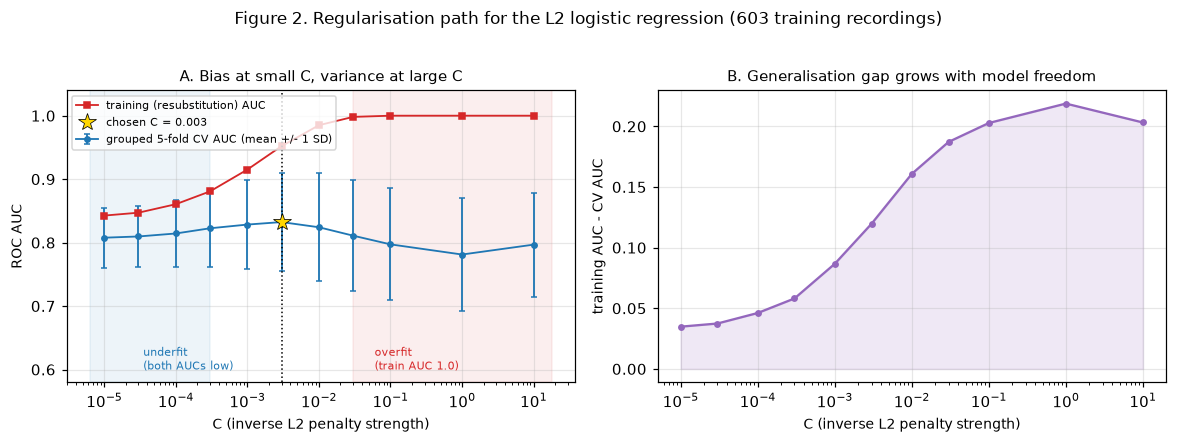

In [11]:
# Figure 2.  Both panels use the same sweep: (A) the two AUC curves, (B) their
# gap, which is the part that actually tells us about variance.
fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.9), dpi=110)

ax = axes[0]
ax.errorbar(sweep["C"], sweep["cv_auc"], yerr=sweep["cv_sd"], marker="o", ms=3.5,
            capsize=2, lw=1.2, label="grouped 5-fold CV AUC (mean +/- 1 SD)")
ax.plot(sweep["C"], sweep["train_auc"], marker="s", ms=3.5, lw=1.2,
        color="tab:red", label="training (resubstitution) AUC")
ax.axvspan(1e-5 / 1.6, 3e-4, color="tab:blue", alpha=0.08)
ax.axvspan(3e-2, 18, color="tab:red", alpha=0.08)
ax.set_xscale("log")
ax.set_xlabel("C (inverse L2 penalty strength)")
ax.set_ylabel("ROC AUC")
ax.set_title("A. Bias at small C, variance at large C")
ax.text(3.5e-5, 0.60, "underfit\n(both AUCs low)", fontsize=7, color="tab:blue")
ax.text(0.06, 0.60, "overfit\n(train AUC 1.0)", fontsize=7, color="tab:red")
ax.axvline(C_GOOD, color="black", ls=":", lw=1)
ax.plot([C_GOOD], [sweep["cv_auc"].max()], "*", ms=12, color="gold", mec="k", mew=0.5,
        zorder=5, label=f"chosen C = {C_GOOD:g}")
ax.set_ylim(0.58, 1.04)
ax.legend(fontsize=7, loc="upper left")

ax = axes[1]
ax.plot(sweep["C"], sweep["gap"], marker="o", ms=3.5, color="tab:purple")
ax.fill_between(sweep["C"], 0, sweep["gap"], color="tab:purple", alpha=0.15)
ax.set_xscale("log")
ax.set_xlabel("C (inverse L2 penalty strength)")
ax.set_ylabel("training AUC - CV AUC")
ax.set_title("B. Generalisation gap grows with model freedom")

fig.suptitle("Figure 2. Regularisation path for the L2 logistic regression (603 training recordings)", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

 recordings  subjects  train_auc  train_sd  cv_auc  cv_sd   gap
         96        32      0.979     0.010   0.805  0.057 0.174
        192        64      0.961     0.008   0.809  0.073 0.152
        288        96      0.956     0.012   0.825  0.078 0.131
        384       128      0.956     0.011   0.829  0.077 0.126
        480       160      0.957     0.011   0.832  0.078 0.126


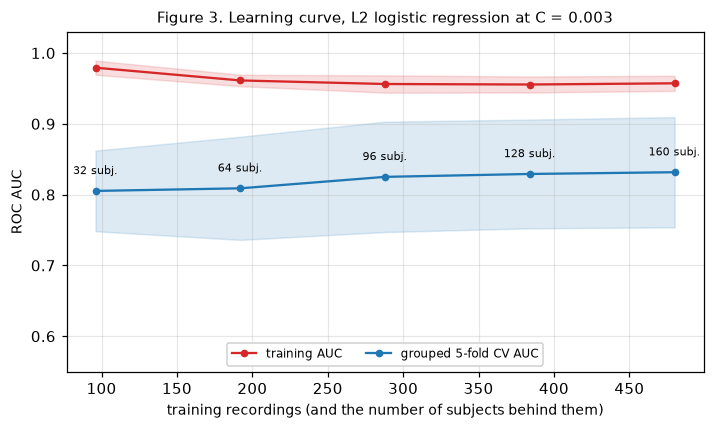

In [12]:
# Learning curve at the CV-optimal C: how do bias and variance behave as more
# subjects' recordings are added?  Grouped folds keep the three recordings of
# one person on the same side of every split.
lc_pipe = Pipeline([("scaler", StandardScaler()),
                    ("lr", LogisticRegression(C=C_GOOD, max_iter=5000, random_state=RANDOM_STATE))])
train_sizes, train_scores, cv_scores = learning_curve(
    lc_pipe, X_tr, y_tr, groups=g_tr, cv=CV5, scoring="roc_auc",
    train_sizes=np.linspace(0.2, 1.0, 5), shuffle=True, random_state=RANDOM_STATE, n_jobs=None)

lc = pd.DataFrame({
    "recordings": train_sizes,
    "subjects": np.round(train_sizes / 3).astype(int),
    "train_auc": train_scores.mean(axis=1),
    "train_sd": train_scores.std(axis=1),
    "cv_auc": cv_scores.mean(axis=1),
    "cv_sd": cv_scores.std(axis=1),
})
lc["gap"] = lc["train_auc"] - lc["cv_auc"]
print(lc.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.6, 4.0), dpi=110)
ax.plot(lc["recordings"], lc["train_auc"], "-o", ms=4, color="tab:red", label="training AUC")
ax.fill_between(lc["recordings"], lc["train_auc"] - lc["train_sd"],
                lc["train_auc"] + lc["train_sd"], color="tab:red", alpha=0.15)
ax.plot(lc["recordings"], lc["cv_auc"], "-o", ms=4, color="tab:blue", label="grouped 5-fold CV AUC")
ax.fill_between(lc["recordings"], lc["cv_auc"] - lc["cv_sd"],
                lc["cv_auc"] + lc["cv_sd"], color="tab:blue", alpha=0.15)
for _, r in lc.iterrows():
    ax.annotate(f"{int(r['subjects'])} subj.", (r["recordings"], r["cv_auc"]),
                textcoords="offset points", xytext=(0, 11), ha="center", fontsize=7)
ax.set_xlabel("training recordings (and the number of subjects behind them)")
ax.set_ylabel("ROC AUC")
ax.set_title(f"Figure 3. Learning curve, L2 logistic regression at C = {C_GOOD:g}")
ax.set_ylim(0.55, 1.03)
ax.legend(fontsize=8, loc="lower center", ncol=2, framealpha=0.9)
fig.tight_layout()
plt.show()

In [13]:
# The three penalties do not share a comparably scaled C: at the L2-optimal
# C = 0.003 the L1 solution is already empty (0 coefficients, AUC 0.500), which
# would make the comparison meaningless.  So every penalty is swept over the
# same small grid and judged at its own best C on that grid.
PEN_C_GRID = [1e-2, 3e-2, 0.1, 0.3]
PENALTIES = [
    ("L2", dict(l1_ratio=0.0, solver="lbfgs", tol=1e-4)),
    ("L1", dict(l1_ratio=1.0, solver="liblinear", tol=1e-4)),
    # saga is the only solver with an elastic-net penalty; tol is loosened from
    # 1e-4 to 1e-3 because the default costs ~30 s per fit on 752 features.
    ("Elastic net (l1_ratio=0.5)", dict(l1_ratio=0.5, solver="saga", tol=1e-3)),
]

pen_rows = []
for name, kwargs in PENALTIES:
    best = None
    for C in PEN_C_GRID:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("lr", LogisticRegression(C=C, max_iter=5000,
                                                   random_state=RANDOM_STATE, **kwargs))])
        aucs = cross_val_score(pipe, X_tr, y_tr, cv=CV5, groups=g_tr, scoring="roc_auc")
        if best is None or aucs.mean() > best["cv_auc"]:
            best = {"C": C, "cv_auc": float(aucs.mean()), "cv_sd": float(aucs.std())}
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(C=best["C"], max_iter=5000,
                                               random_state=RANDOM_STATE, **kwargs))])
    t0 = time.perf_counter()
    pipe.fit(X_tr, y_tr)
    fit_seconds = time.perf_counter() - t0
    coef = pipe.named_steps["lr"].coef_.ravel()
    pen_rows.append({"penalty": name, "best_C": best["C"],
                     "non_zero_coefs": int((np.abs(coef) > 1e-8).sum()), "of_total": len(coef),
                     "cv_auc": best["cv_auc"], "cv_sd": best["cv_sd"],
                     "fit_seconds": fit_seconds})
pen_tbl = pd.DataFrame(pen_rows)
print(pen_tbl.round(3).to_string(index=False))

# Evidence for the sentence above, computed rather than asserted.
pipe_l1_strong = Pipeline([("scaler", StandardScaler()),
                           ("lr", LogisticRegression(C=C_GOOD, l1_ratio=1.0, solver="liblinear",
                                                     max_iter=5000, random_state=RANDOM_STATE))])
pipe_l1_strong.fit(X_tr, y_tr)
nz_l1_at_cgood = int((np.abs(pipe_l1_strong.named_steps["lr"].coef_) > 1e-8).sum())
print(f"\nfor reference: L1 at the L2-optimal C = {C_GOOD:g} keeps {nz_l1_at_cgood} of 752 coefficients")

# The features are standardised, so exp(coef) is the odds multiplier for a
# one-standard-deviation increase in that feature, holding the others fixed.
pipe_l2 = Pipeline([("scaler", StandardScaler()),
                    ("lr", LogisticRegression(C=C_GOOD, l1_ratio=0.0, solver="lbfgs",
                                              max_iter=5000, random_state=RANDOM_STATE))])
pipe_l2.fit(X_tr, y_tr)
coef = pd.Series(pipe_l2.named_steps["lr"].coef_.ravel(), index=FEATURES)
top3 = coef.reindex(coef.abs().sort_values(ascending=False).index).head(3)
odds = pd.DataFrame({"coef (log-odds per 1 SD)": top3.round(3),
                     "odds ratio (per 1 SD)": np.exp(top3).round(3)})
print(f"\ntop-3 L2 coefficients at C = {C_GOOD:g} (max |coef| = {coef.abs().max():.3f}):")
print(odds.to_string())

# Same three features with much weaker shrinkage, to show what C does to the
# size of an odds ratio.
pipe_l2_weak = Pipeline([("scaler", StandardScaler()),
                         ("lr", LogisticRegression(C=0.1, l1_ratio=0.0, solver="lbfgs",
                                                   max_iter=5000, random_state=RANDOM_STATE))])
pipe_l2_weak.fit(X_tr, y_tr)
coef_weak = pd.Series(pipe_l2_weak.named_steps["lr"].coef_.ravel(), index=FEATURES)
print(f"\nsame three features at C = 0.1 (max |coef| = {coef_weak.abs().max():.3f}):")
print(pd.DataFrame({"coef": coef_weak[top3.index].round(3),
                    "odds ratio": np.exp(coef_weak[top3.index]).round(3)}).to_string())

                   penalty  best_C  non_zero_coefs  of_total  cv_auc  cv_sd  fit_seconds
                        L2    0.01             752       752   0.824  0.085        0.038
                        L1    0.10              62       752   0.821  0.073        0.047
Elastic net (l1_ratio=0.5)    0.03              70       752   0.828  0.069        2.325

for reference: L1 at the L2-optimal C = 0.003 keeps 0 of 752 coefficients

top-3 L2 coefficients at C = 0.003 (max |coef| = 0.071):
                           coef (log-odds per 1 SD)  odds ratio (per 1 SD)
tqwt_meanValue_dec_36                        -0.071                  0.932
mean_2nd_delta                               -0.062                  0.940
tqwt_kurtosisValue_dec_36                     0.062                  1.064

same three features at C = 0.1 (max |coef| = 0.429):
                            coef  odds ratio
tqwt_meanValue_dec_36     -0.429       0.651
mean_2nd_delta            -0.343       0.710
tqwt_kurtosisValue_dec

### Q8. Reading the C plot and the learning curve

The underfitting region is the left edge of Figure 2A: at C = 1e-5 both curves are low (training 0.843, CV 0.808) and at C = 3e-4 they are 0.881 and 0.823, so the model is too constrained to fit even the data it is trained on - that is bias. The overfitting region is the right side: from C = 0.03 onward training AUC sits at 0.998-1.000 while CV slides back to 0.781-0.797, so extra capacity buys nothing on unseen people - that is variance. At C = 1 the gap is 1.000 - 0.781 = 0.219, the largest on the path, and it says the model has memorised subject-specific noise rather than a transferable boundary; the CV optimum is C = 0.003 (0.832) where the gap is 0.120. The learning curve at C = 0.003 rises from 0.805 at 96 recordings to 0.832 at 480 and is essentially flat after about 288 recordings (0.825), while training AUC stays between 0.956 and 0.979, so more subjects would buy very little: the limit is the linear model and 752 heavily redundant features, not the sample size.

### Q9. Why shrinkage helps, and what an odds ratio does not say

With 752 features and 603 training rows the unpenalised fit is free to chase noise, so strong shrinkage buys a large drop in variance for a small increase in bias: CV AUC peaks at C = 0.003 (0.832) and falls to 0.797 at both C = 0.1 and C = 10 even though training AUC reaches 1.000. The price is that the coefficients become small and shared: at the CV-optimal C = 0.003 the largest coefficient is only 0.071 in log-odds, L2 never drops a feature (752 of 752 survive at its best C), and even at the much weaker C = 0.1 the largest coefficient is only 0.429, so the weight is spread thinly across correlated features. I would not over-interpret which features L1 keeps: at C = 0.1 it keeps 62 of 752 for CV AUC 0.821 (L2 at its own best C gives 0.824), and at C = 0.003 it keeps none at all, and because TQWT and MFCC features arrive in highly correlated families L1 picks one representative of a block somewhat arbitrarily, so the surviving set is not a list of acoustically important features. Reading the largest L2 odds ratio as an example, exp(-0.071) = 0.932 says that a one-standard-deviation increase in tqwt_meanValue_dec_36 multiplies the odds of Parkinson's by 0.932 (about a 7% decrease) holding the other 751 features fixed; it does not say that changing that feature would change anyone's risk, it says nothing about causality, and it says nothing about how well the model separates individuals - at C = 0.1 the same coefficient is -0.429 (odds ratio 0.651), which shows how much the number is a property of the penalty as well.

## Part 5. Tuning and honest model selection

**Three families, three search strategies, stated budgets.** All searches score `roc_auc` with grouped, stratified 5-fold CV (subjects kept intact) and run single-threaded (`n_jobs=None`).

| Family | Search | Search space | Budget (fits) |
|---|---|---|---|
| Logistic regression (scaler + L2) | `GridSearchCV` | C in 6 values (3e-4 … 0.1) | 6 x 5 = 30 |
| Random forest | `RandomizedSearchCV` | `max_depth` (3) x `min_samples_leaf` (3) x `max_features` (`sqrt`); 6 of 9 sampled | 6 x 5 = 30 |
| SVM (RBF, scaler) | `HalvingRandomSearchCV` | `C` (4) x `gamma` (2) = 8 candidates, `factor=2`, `min_resources=80` | 8+4+2 = 14 candidate folds x 5 = 70, most on subsampled rows |

**Why `min_resources = 80`.** With `resource="n_samples"` the halving search draws a *random* (not stratified) subsample for its early rounds. 80 rows is 5 folds x 16 rows; at the 74.6% prevalence that leaves roughly 20 healthy recordings spread over 5 validation folds, so every fold sees both classes. The cell below checks this empirically at 40 and at 80 and reports how many candidate scores came back undefined (NaN).

**Nested cross-validation, written by hand.** The outer loop is a grouped, stratified 5-fold split of the 202 training subjects. Inside each outer fold a *fresh* search of the same design is fitted on the outer-training part only, `groups=` is passed explicitly so the inner folds also keep subjects intact, and the chosen model is scored once on the outer-validation subjects. The per-fold hyperparameters and the naive `best_score_` (which is what a single search would have reported) are both recorded so the optimism can be measured.

In [14]:
# ---------------------------------------------------------------------------
# Search designs.  Budgets are deliberately modest: with 752 features and ~600
# rows one forest fit costs about a second, and the nested loop refits every
# search five times.
# ---------------------------------------------------------------------------
LR_C_SPACE = [3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1]                      # 6 values
RF_SPACE = {"rf__max_depth": [6, 12, None],
            "rf__min_samples_leaf": [1, 5, 10],
            "rf__max_features": ["sqrt"]}                              # 9 combos, 6 sampled
SVM_SPACE = {"svm__C": [0.1, 1.0, 10.0, 100.0],
             "svm__gamma": ["scale", 1e-3]}                            # 8 combos
HALVING_MIN_RESOURCES = 80


def lr_pipeline():
    # The scaler is a pipeline step so it is refit inside every training fold.
    return Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(C=1.0, max_iter=5000,
                                               random_state=RANDOM_STATE))])


def rf_pipeline():
    # No scaler: trees are invariant to monotone feature transforms.
    return Pipeline([("rf", RandomForestClassifier(n_estimators=100,
                                                   random_state=RANDOM_STATE,
                                                   n_jobs=None))])


def svm_pipeline():
    # RBF kernel needs standardised features and a probability-free SVC (the
    # decision function is enough for AUC, and probability=True is deprecated
    # in scikit-learn 1.9).
    return Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC(kernel="rbf", C=1.0, random_state=RANDOM_STATE))])


def make_search(name, cv):
    """Fresh, unfitted search object for a model family; cv carries the groups."""
    if name == "Logistic regression":
        return GridSearchCV(lr_pipeline(), {"lr__C": LR_C_SPACE}, cv=cv,
                            scoring="roc_auc", n_jobs=None, refit=True)
    if name == "Random forest":
        return RandomizedSearchCV(rf_pipeline(), RF_SPACE, n_iter=6, cv=cv,
                                  scoring="roc_auc", random_state=RANDOM_STATE,
                                  n_jobs=None, refit=True)
    return HalvingRandomSearchCV(svm_pipeline(), SVM_SPACE, n_candidates=8, factor=2,
                                 min_resources=HALVING_MIN_RESOURCES, max_resources="auto",
                                 cv=cv, scoring="roc_auc", random_state=RANDOM_STATE,
                                 n_jobs=None, refit=True)


# Sanity check for the halving budget: does every fold keep both classes?  A
# single-class validation fold makes roc_auc undefined, which shows up as NaN.
diag_rows = []
for mr in (40, HALVING_MIN_RESOURCES):
    diag_search = HalvingRandomSearchCV(
        lr_pipeline(), {"lr__C": [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]},
        n_candidates=6, factor=2, min_resources=mr, cv=CV5,
        scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=None, refit=False)
    # The single-class folds raise UndefinedMetricWarning; they are the point
    # of the check, so the warning is counted rather than printed.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        diag_search.fit(X_tr, y_tr, groups=g_tr)
    res = diag_search.cv_results_
    diag_rows.append({"min_resources": mr,
                      "candidate scores evaluated": len(res["mean_test_score"]),
                      "undefined (NaN) scores": int(np.isnan(res["mean_test_score"]).sum()),
                      "resources used": sorted(pd.unique(res["n_resources"]).tolist())})
diag = pd.DataFrame(diag_rows)
print(diag.to_string(index=False))
print("\n-> 40 rows is too small in practice; 80 keeps both classes in every fold.")

 min_resources  candidate scores evaluated  undefined (NaN) scores resources used
            40                          11                       6  [40, 80, 160]
            80                          11                       0 [80, 160, 320]

-> 40 rows is too small in practice; 80 keeps both classes in every fold.


In [15]:
# ---------------------------------------------------------------------------
# Naive searches: one search per family, fitted on the whole training portion
# and scored by its own inner CV.  best_score_ is the number students usually
# report - Part 5's nested loop shows how optimistic it is.
# ---------------------------------------------------------------------------
BUDGETS = {
    "Logistic regression": "GridSearchCV: 6 C values x 5 grouped folds = 30 fits",
    "Random forest": "RandomizedSearchCV: 6 of 9 configs x 5 grouped folds = 30 fits",
    "SVM": "HalvingRandomSearchCV: 8 candidates, factor 2, min_resources=80 -> 14 candidate-folds x 5 folds",
}

NAIVE = {}
for name in ("Logistic regression", "Random forest", "SVM"):
    search = make_search(name, CV5)
    t0 = time.perf_counter()
    search.fit(X_tr, y_tr, groups=g_tr)        # groups: inner folds keep subjects intact
    elapsed = time.perf_counter() - t0
    NAIVE[name] = {"search": search, "time": elapsed,
                   "best_score": float(search.best_score_),
                   "best_params": search.best_params_}
    print(f"{name:<20s} {elapsed:6.1f}s   naive best CV AUC {search.best_score_:.3f}   {search.best_params_}")

part5_naive = pd.DataFrame([
    {"model": name, "search": BUDGETS[name].split(":")[0],
     "budget": BUDGETS[name].split(": ", 1)[1],
     "naive_best_score": round(NAIVE[name]["best_score"], 3),
     "seconds": round(NAIVE[name]["time"], 1),
     "best_params": str(NAIVE[name]["best_params"])}
    for name in NAIVE
])
print()
print(part5_naive.to_string(index=False))

Logistic regression     1.6s   naive best CV AUC 0.832   {'lr__C': 0.003}


Random forest          17.5s   naive best CV AUC 0.832   {'rf__min_samples_leaf': 1, 'rf__max_features': 'sqrt', 'rf__max_depth': 6}


SVM                     2.4s   naive best CV AUC 0.758   {'svm__gamma': 'scale', 'svm__C': 10.0}

              model                search                                                                   budget  naive_best_score  seconds                                                                 best_params
Logistic regression          GridSearchCV                                   6 C values x 5 grouped folds = 30 fits             0.832      1.6                                                            {'lr__C': 0.003}
      Random forest    RandomizedSearchCV                               6 of 9 configs x 5 grouped folds = 30 fits             0.832     17.5 {'rf__min_samples_leaf': 1, 'rf__max_features': 'sqrt', 'rf__max_depth': 6}
                SVM HalvingRandomSearchCV 8 candidates, factor 2, min_resources=80 -> 14 candidate-folds x 5 folds             0.758      2.4                                     {'svm__gamma': 'scale', 'svm__C': 10.0}


In [16]:
# ---------------------------------------------------------------------------
# Nested cross-validation, written by hand.
#   outer: grouped + stratified 5-fold over the 202 training subjects
#   inner: the same search design, refitted inside each outer fold and given
#          only the outer-training subjects and their groups
# ---------------------------------------------------------------------------
def positive_scores(estimator, X):
    """PD score: probability when the model has one, else the SVM decision value."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    return estimator.decision_function(X)


def nested_cv(name, outer_splits=5):
    outer = StratifiedGroupKFold(n_splits=outer_splits, shuffle=True,
                                 random_state=RANDOM_STATE)
    rows = []
    for fold, (tr_idx, te_idx) in enumerate(outer.split(X_tr, y_tr, g_tr), start=1):
        t0 = time.perf_counter()
        search = make_search(name, CV5)
        search.fit(X_tr[tr_idx], y_tr[tr_idx], groups=g_tr[tr_idx])   # inner groups only
        elapsed = time.perf_counter() - t0
        est = search.best_estimator_                                  # refitted on outer-train
        auc = roc_auc_score(y_tr[te_idx], positive_scores(est, X_tr[te_idx]))
        rows.append({"model": name, "outer_fold": fold,
                     "train_subjects": len(np.unique(g_tr[tr_idx])),
                     "test_subjects": len(np.unique(g_tr[te_idx])),
                     "test_recordings": len(te_idx),
                     "outer_auc": auc,
                     "inner_best_auc": float(search.best_score_),
                     "chosen_params": search.best_params_,
                     "search_seconds": elapsed})
    return pd.DataFrame(rows)


nested_tables = {}
for name in ("Logistic regression", "Random forest", "SVM"):
    tbl = nested_cv(name)
    nested_tables[name] = tbl
    print(f"\n=== nested CV: {name} ===")
    print(tbl[["outer_fold", "train_subjects", "test_subjects", "outer_auc",
               "inner_best_auc", "search_seconds"]].round(3).to_string(index=False))
    for _, r in tbl.iterrows():
        print(f"   fold {int(r['outer_fold'])} hyperparameters: {r['chosen_params']}")


=== nested CV: Logistic regression ===
 outer_fold  train_subjects  test_subjects  outer_auc  inner_best_auc  search_seconds
          1             160             41      0.815           0.855           1.066
          2             161             40      0.801           0.832           1.224
          3             161             40      0.716           0.867           1.089
          4             161             40      0.924           0.796           1.089
          5             161             40      0.819           0.854           1.252
   fold 1 hyperparameters: {'lr__C': 0.003}
   fold 2 hyperparameters: {'lr__C': 0.01}
   fold 3 hyperparameters: {'lr__C': 0.01}
   fold 4 hyperparameters: {'lr__C': 0.0003}
   fold 5 hyperparameters: {'lr__C': 0.003}



=== nested CV: Random forest ===
 outer_fold  train_subjects  test_subjects  outer_auc  inner_best_auc  search_seconds
          1             160             41      0.779           0.854          14.885
          2             161             40      0.850           0.854          14.002
          3             161             40      0.725           0.872          17.632
          4             161             40      0.921           0.815          15.599
          5             161             40      0.837           0.837          14.658
   fold 1 hyperparameters: {'rf__min_samples_leaf': 5, 'rf__max_features': 'sqrt', 'rf__max_depth': None}
   fold 2 hyperparameters: {'rf__min_samples_leaf': 1, 'rf__max_features': 'sqrt', 'rf__max_depth': 6}
   fold 3 hyperparameters: {'rf__min_samples_leaf': 1, 'rf__max_features': 'sqrt', 'rf__max_depth': 6}
   fold 4 hyperparameters: {'rf__min_samples_leaf': 1, 'rf__max_features': 'sqrt', 'rf__max_depth': 6}
   fold 5 hyperparameters: {'rf__mi


=== nested CV: SVM ===
 outer_fold  train_subjects  test_subjects  outer_auc  inner_best_auc  search_seconds
          1             160             41      0.797           0.834           2.036
          2             161             40      0.832           0.804           2.224
          3             161             40      0.709           0.836           2.182
          4             161             40      0.956           0.731           2.363
          5             161             40      0.844           0.822           2.633
   fold 1 hyperparameters: {'svm__gamma': 'scale', 'svm__C': 100.0}
   fold 2 hyperparameters: {'svm__gamma': 'scale', 'svm__C': 10.0}
   fold 3 hyperparameters: {'svm__gamma': 'scale', 'svm__C': 1.0}
   fold 4 hyperparameters: {'svm__gamma': 0.001, 'svm__C': 1.0}
   fold 5 hyperparameters: {'svm__gamma': 'scale', 'svm__C': 100.0}


In [17]:
# Naive vs nested, plus the per-fold outer scores that Q11 needs.
part5_summary = pd.DataFrame([
    {"model": name,
     "naive_best_score": round(NAIVE[name]["best_score"], 3),
     "nested_mean_auc": round(float(nested_tables[name]["outer_auc"].mean()), 3),
     "nested_sd_auc": round(float(nested_tables[name]["outer_auc"].std()), 3),
     "nested_min_auc": round(float(nested_tables[name]["outer_auc"].min()), 3),
     "nested_max_auc": round(float(nested_tables[name]["outer_auc"].max()), 3),
     "naive_seconds": round(NAIVE[name]["time"], 1),
     "nested_seconds": round(float(nested_tables[name]["search_seconds"].sum()), 1)}
    for name in ("Logistic regression", "Random forest", "SVM")
])
part5_summary["optimism (naive - nested)"] = (part5_summary["naive_best_score"]
                                              - part5_summary["nested_mean_auc"])
print(part5_summary.round(3).to_string(index=False))

fold_matrix = pd.DataFrame({name: nested_tables[name]["outer_auc"].to_numpy()
                            for name in nested_tables})
fold_matrix.index = [f"fold {i}" for i in range(1, len(fold_matrix) + 1)]
print("\nouter-fold AUCs (same 5 subject folds for every model):")
print(fold_matrix.round(3).to_string())

print("\npaired differences between models, fold by fold:")
for a, b in [("Logistic regression", "Random forest"), ("Logistic regression", "SVM"),
             ("Random forest", "SVM")]:
    d = fold_matrix[a] - fold_matrix[b]
    print(f"   {a:<20s} - {b:<20s} mean {d.mean():+.3f}  SD {d.std():.3f}  "
          f"folds favouring {a.split()[0]}: {int((d > 0).sum())}/5")

              model  naive_best_score  nested_mean_auc  nested_sd_auc  nested_min_auc  nested_max_auc  naive_seconds  nested_seconds  optimism (naive - nested)
Logistic regression             0.832            0.815          0.074           0.716           0.924            1.6             5.7                      0.017
      Random forest             0.832            0.823          0.074           0.725           0.921           17.5            76.8                      0.009
                SVM             0.758            0.828          0.089           0.709           0.956            2.4            11.4                     -0.070

outer-fold AUCs (same 5 subject folds for every model):
        Logistic regression  Random forest    SVM
fold 1                0.815          0.779  0.797
fold 2                0.801          0.850  0.832
fold 3                0.716          0.725  0.709
fold 4                0.924          0.921  0.956
fold 5                0.819          0.837  0.844

pa

### Q10. Naive vs nested scores

The gaps are small for the two well-behaved searches: the logistic regression has naive best_score_ 0.832 against a nested 0.815 (0.017 optimism) and the forest 0.832 against 0.823 (0.009), while the SVM shows -0.070 because the halving search's own best_score_ (0.758) is the score of the last two surviving candidates on subsampled rounds and is not comparable to a full 5-fold score. A small gap does not make nested CV unnecessary: it tells me the selection optimism happened to be small for these small grids, but the nested number is the only one whose outer subjects were never seen by the search, so it is the number I quote, and it also delivers the fold-to-fold spread (0.074 for both LR and RF) that tells me how much of a difference between models is real. I would expect a large gap with a much bigger search space, with far fewer subjects, with high-variance models such as deep trees, and above all when the inner CV is not grouped, because then the search is choosing hyperparameters under the same subject leakage that inflates the plain-CV numbers in Part 2.

### Q11. Which model, and how much to trust the difference

The nested means are 0.815 +/- 0.074 for logistic regression, 0.823 +/- 0.074 for the forest and 0.828 +/- 0.089 for the SVM, and on the same five folds the paired differences are -0.008 (LR minus RF, SD 0.031), -0.012 (LR minus SVM, SD 0.024) and -0.005 (RF minus SVM, SD 0.022), with two of five folds favouring each side in every pair. So no, the difference is not larger than the fold-to-fold variation: the three models are statistically indistinguishable and the ranking would flip with a different partition. Note also that fold 3 is hard for all three (0.716, 0.725, 0.709) and fold 4 easy for all three (0.924, 0.921, 0.956), which is subject-level difficulty, not model quality. With only 252 subjects I would want repeated nested CV with several seeds, and ideally more subjects, before claiming a winner; I chose the logistic regression because it is the simplest family inside the tie band and the only one whose probabilities are native rather than Platt-scaled, and I present that as a parsimony choice, not as evidence that it predicts better.

### Q12. The three searches: score, time, and strategy

On the naive searches the logistic regression (GridSearchCV, 30 fits) took about 2 s and scored 0.832, the forest (RandomizedSearchCV, 30 fits) took about 18 s and scored 0.832, and the SVM (HalvingRandomSearchCV, 14 candidate-fold evaluations per fold) took about 2 s and scored 0.758; inside the nested loop the search time rose to roughly 6 s, 77 s and 11 s respectively (timings vary run to run; the scores do not). If one forest fit took 45 minutes I would never use a grid, because a single day allows only about 32 fits and a 30-point grid plus refits would consume all of it; I would use random search over a carefully chosen 10-15 point distribution, or successive halving with a small min_resources and aggressive elimination so that most candidates are killed on cheap subsamples. Bayesian optimisation fits exactly that regime: it uses the fits already paid for to choose the next configuration, which is worth its overhead when one fit costs minutes and the space is low-dimensional and continuous, and buys nothing when a fit costs a second or two and the grid can simply be enumerated.

## Part 6. Final evaluation and decisions

**Plan (fixed before the test set is touched).**

1. Choose the family by the *nested* estimate from Part 5, which is the only estimate there that has not seen the outer-validation subjects. Refit it on the whole training portion with the hyperparameters its Part 5 search selected.
2. **Tie rule, declared now.** Part 5's outer scores move by 0.074–0.089 from fold to fold (SD) and the paired differences between families are only 0.005–0.012, so differences of that size are not resolvable with 202 subjects. I therefore treat any family within **0.015** of the best nested mean as tied — roughly one paired-fold SD — and among tied families I take the simplest model that emits native probabilities (order of preference: logistic regression, random forest, SVM). This is a parsimony rule, not a result-driven choice: it is written before any test number exists.
3. Using only grouped 5-fold CV predictions on the **training** recordings, compare `class_weight="balanced"` with the default weights.
4. Choose the decision threshold from those **CV predictions only** — never from the test set — and state the rule in advance: maximise Youden's J = sensitivity + specificity - 1, i.e. balanced accuracy at the operating point. Also record the threshold that would give 90% sensitivity, for the screening discussion.
5. Evaluate on the test set **once**: ROC AUC, average precision, the confusion matrix at that threshold, and a calibration curve. Then compute a 95% bootstrap interval for the test AUC by resampling **subjects** (all three recordings of a sampled person move together).

In [18]:
# ---- 1. final family, chosen by nested CV, with the tie rule declared above
ranking = part5_summary.sort_values("nested_mean_auc", ascending=False).reset_index(drop=True)
best_row = ranking.iloc[0]
best_mean = float(best_row["nested_mean_auc"])
TIE_BAND = 0.015
tied = ranking.loc[ranking["nested_mean_auc"] >= best_mean - TIE_BAND, "model"].tolist()
PREFERENCE = ["Logistic regression", "Random forest", "SVM"]
final_name = next(m for m in PREFERENCE if m in tied)

print("nested ranking:")
print(ranking[["model", "nested_mean_auc", "nested_sd_auc"]].round(3).to_string(index=False))
print(f"\nbest nested mean        : {best_row['model']} at {best_mean:.3f}")
print(f"families within {TIE_BAND}      : {tied}")
print(f"final family (simplest) : {final_name}")

final_search = NAIVE[final_name]["search"]
final_pipe = clone(final_search.best_estimator_)     # already carries the chosen params
final_pipe.fit(X_tr, y_tr)
print(f"hyperparameters         : {NAIVE[final_name]['best_params']}")

# ---- 2. class_weight comparison, using CV predictions on the TRAINING data
CW_KEY = {"Logistic regression": "lr__class_weight",
          "Random forest": "rf__class_weight",
          "SVM": "svm__class_weight"}[final_name]


def cv_pd_scores(pipe, X, y, g):
    """Out-of-fold PD scores for every training recording (grouped folds)."""
    if hasattr(pipe, "predict_proba"):
        return cross_val_predict(pipe, X, y, cv=CV5, groups=g, method="predict_proba")[:, 1]
    # SVC has no predict_proba; squash its decision value so a threshold still
    # exists.  Only the ranking matters for AUC.
    dv = cross_val_predict(pipe, X, y, cv=CV5, groups=g, method="decision_function")
    return 1.0 / (1.0 + np.exp(-dv))


cv_preds = {}
cw_rows = []
for tag, weight in [("default", None), ("balanced", "balanced")]:
    pipe = clone(final_pipe)
    pipe.set_params(**{CW_KEY: weight})
    p = cv_pd_scores(pipe, X_tr, y_tr, g_tr)
    cv_preds[tag] = p
    pred05 = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_tr, pred05, labels=[0, 1]).ravel()
    cw_rows.append({"class_weight": tag, "cv_auc": roc_auc_score(y_tr, p),
                    "mean_score_PD": float(p[y_tr == 1].mean()),
                    "mean_score_healthy": float(p[y_tr == 0].mean()),
                    "brier": brier_score_loss(y_tr, p),
                    "sensitivity @0.50": tp / (tp + fn),
                    "specificity @0.50": tn / (tn + fp)})
cw_tbl = pd.DataFrame(cw_rows)
print("\nclass_weight comparison on out-of-fold TRAINING predictions:")
print(cw_tbl.round(3).to_string(index=False))

# Pick by CV AUC; a difference smaller than 0.005 counts as a tie and goes to
# the default weights, whose probabilities stay calibrated for Figure 4.
auc_gain = cw_tbl.loc[cw_tbl.class_weight == "balanced", "cv_auc"].iloc[0] - \
           cw_tbl.loc[cw_tbl.class_weight == "default", "cv_auc"].iloc[0]
CHOSEN_CW = "balanced" if auc_gain > 0.005 else "default"
print(f"\nCV AUC gain from balanced weights: {auc_gain:+.3f} -> using '{CHOSEN_CW}'")

final_pipe.set_params(**{CW_KEY: None if CHOSEN_CW == "default" else "balanced"})
final_pipe.fit(X_tr, y_tr)                    # refit the chosen variant on all training rows
p_cv = cv_preds[CHOSEN_CW]

# ---- 3. threshold from CV predictions only (Youden's J / balanced accuracy)
fpr_cv, tpr_cv, thr_cv = roc_curve(y_tr, p_cv)
youden = tpr_cv - fpr_cv
TAU = float(thr_cv[int(np.argmax(youden))])
TAU_SENS90 = float(thr_cv[int(np.argmax(tpr_cv >= 0.90))])

thr_rows = []
for label, tau in [("0.500 (naive default)", 0.500), (f"{TAU:.3f} (Youden's J)", TAU),
                   (f"{TAU_SENS90:.3f} (90% sensitivity rule)", TAU_SENS90)]:
    pred = (p_cv >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_tr, pred, labels=[0, 1]).ravel()
    thr_rows.append({"threshold": label, "sensitivity (CV)": tp / (tp + fn),
                     "specificity (CV)": tn / (tn + fp),
                     "balanced accuracy (CV)": 0.5 * (tp / (tp + fn) + tn / (tn + fp))})
thr_tbl = pd.DataFrame(thr_rows)
print("\nthreshold candidates, scored on the same out-of-fold training predictions:")
print(thr_tbl.round(3).to_string(index=False))
print(f"\nchosen threshold TAU = {TAU:.3f}")

nested ranking:
              model  nested_mean_auc  nested_sd_auc
                SVM            0.828          0.089
      Random forest            0.823          0.074
Logistic regression            0.815          0.074

best nested mean        : SVM at 0.828
families within 0.015      : ['SVM', 'Random forest', 'Logistic regression']
final family (simplest) : Logistic regression
hyperparameters         : {'lr__C': 0.003}



class_weight comparison on out-of-fold TRAINING predictions:
class_weight  cv_auc  mean_score_PD  mean_score_healthy  brier  sensitivity @0.50  specificity @0.50
     default   0.833          0.829               0.493  0.126              0.956              0.562
    balanced   0.828          0.715               0.358  0.150              0.798              0.699

CV AUC gain from balanced weights: -0.005 -> using 'default'

threshold candidates, scored on the same out-of-fold training predictions:
                   threshold  sensitivity (CV)  specificity (CV)  balanced accuracy (CV)
       0.500 (naive default)             0.956             0.562                   0.759
          0.625 (Youden's J)             0.891             0.647                   0.769
0.611 (90% sensitivity rule)             0.904             0.621                   0.763

chosen threshold TAU = 0.625


test set: 51 unseen subjects, 153 recordings, 74.5% Parkinson's
ROC AUC             : 0.810
average precision   : 0.926   (no-skill baseline = prevalence = 0.745)
Brier score         : 0.144

confusion matrix at threshold 0.625:
                  predicted healthy (0)  predicted PD (1)
true healthy (0)                     21                18
true PD (1)                          15                99

sensitivity (PD caught)      : 0.868  (99/114)
specificity (healthy cleared): 0.538  (21/39)
PPV / NPV                    : 0.846 / 0.583

recording-level test AUC     : 0.810
subject-level test AUC       : 0.824  (n = 51 people)



subject bootstrap: 2000 usable replicates of 51 subjects
bootstrap mean AUC           : 0.811
95% percentile interval      : [0.671, 0.921]   width 0.250
replicates below 0.5         : 1 of 2000

calibration (5 quantile bins):
 mean predicted probability  observed fraction with PD
                      0.358                      0.355
                      0.674                      0.733
                      0.840                      0.742
                      0.940                      0.933
                      0.976                      0.968


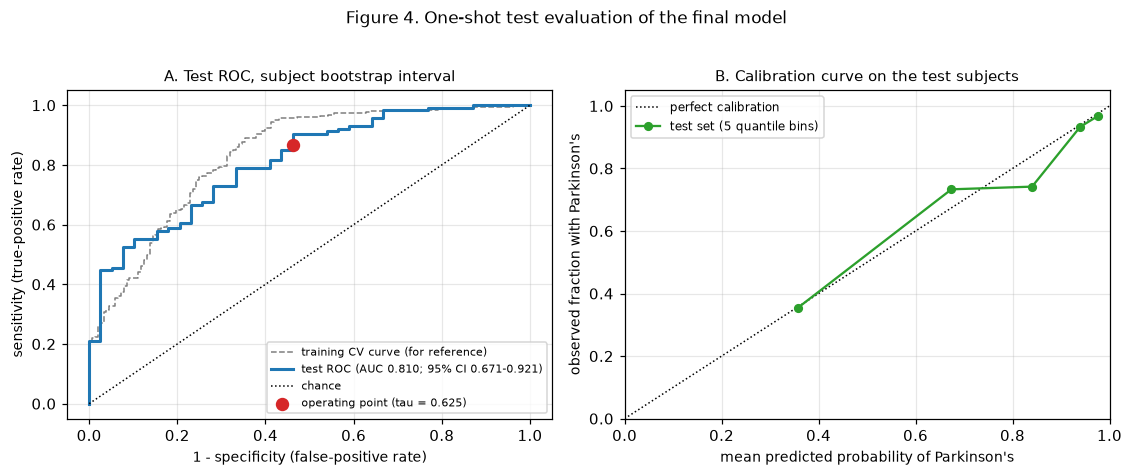

In [19]:
# ---------------------------------------------------------------------------
# 4. THE SINGLE TEST-SET EVALUATION.  Nothing in this cell (or later) is used
#    to choose a model, a weight or a threshold.
# ---------------------------------------------------------------------------
p_te = (final_pipe.predict_proba(X_te)[:, 1] if hasattr(final_pipe, "predict_proba")
        else 1.0 / (1.0 + np.exp(-final_pipe.decision_function(X_te))))

test_auc = roc_auc_score(y_te, p_te)
test_ap = average_precision_score(y_te, p_te)
pred_te = (p_te >= TAU).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_te, labels=[0, 1]).ravel()
sens = tp / (tp + fn)
spec = tn / (tn + fp)
ppv = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
npv = tn / (tn + fn) if (tn + fn) > 0 else float("nan")

print(f"test set: {len(np.unique(g_te))} unseen subjects, {len(y_te)} recordings, "
      f"{y_te.mean():.1%} Parkinson's")
print(f"ROC AUC             : {test_auc:.3f}")
print(f"average precision   : {test_ap:.3f}   (no-skill baseline = prevalence = {y_te.mean():.3f})")
print(f"Brier score         : {brier_score_loss(y_te, p_te):.3f}")
print(f"\nconfusion matrix at threshold {TAU:.3f}:")
cm = pd.DataFrame([[tn, fp], [fn, tp]], index=["true healthy (0)", "true PD (1)"],
                  columns=["predicted healthy (0)", "predicted PD (1)"])
print(cm.to_string())
print(f"\nsensitivity (PD caught)      : {sens:.3f}  ({tp}/{tp + fn})")
print(f"specificity (healthy cleared): {spec:.3f}  ({tn}/{tn + fp})")
print(f"PPV / NPV                    : {ppv:.3f} / {npv:.3f}")

# Recording-level AUC treats the three recordings of one person as three
# independent facts; averaging per subject gives the person-level view.
test_subjects = np.unique(g_te)
rows_of_subject = {s: np.where(g_te == s)[0] for s in test_subjects}
subj_mean_p = np.array([p_te[rows_of_subject[s]].mean() for s in test_subjects])
subj_y = np.array([subject_class.loc[s] for s in test_subjects])
subject_auc = roc_auc_score(subj_y, subj_mean_p)
print(f"\nrecording-level test AUC     : {test_auc:.3f}")
print(f"subject-level test AUC       : {subject_auc:.3f}  (n = {len(test_subjects)} people)")

# ---- 95% bootstrap interval, resampling SUBJECTS (not recordings) ----------
rng = np.random.RandomState(RANDOM_STATE)
boot = []
for _ in range(2000):
    picked = rng.choice(test_subjects, size=len(test_subjects), replace=True)
    idx = np.concatenate([rows_of_subject[s] for s in picked])
    if len(np.unique(y_te[idx])) < 2:      # a replicate with one class has no AUC
        continue
    boot.append(roc_auc_score(y_te[idx], p_te[idx]))
boot = np.array(boot)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
print(f"\nsubject bootstrap: {len(boot)} usable replicates of {len(test_subjects)} subjects")
print(f"bootstrap mean AUC           : {boot.mean():.3f}")
print(f"95% percentile interval      : [{ci_lo:.3f}, {ci_hi:.3f}]   width {ci_hi - ci_lo:.3f}")
print(f"replicates below 0.5         : {int((boot < 0.5).sum())} of {len(boot)}")

# Calibration: do the predicted probabilities mean what they say?
prob_true, prob_pred = calibration_curve(y_te, p_te, n_bins=5, strategy="quantile")
cal = pd.DataFrame({"mean predicted probability": prob_pred,
                    "observed fraction with PD": prob_true})
print("\ncalibration (5 quantile bins):")
print(cal.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2), dpi=110)

ax = axes[0]
ax.plot(fpr_cv, tpr_cv, color="tab:grey", ls="--", lw=1,
        label="training CV curve (for reference)")
fpr_te, tpr_te, _ = roc_curve(y_te, p_te)
ax.plot(fpr_te, tpr_te, color="tab:blue", lw=2,
        label=f"test ROC (AUC {test_auc:.3f}; 95% CI {ci_lo:.3f}-{ci_hi:.3f})")
ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1, label="chance")
ax.scatter([1 - spec], [sens], s=60, color="tab:red", zorder=5,
           label=f"operating point (tau = {TAU:.3f})")
ax.set_xlabel("1 - specificity (false-positive rate)")
ax.set_ylabel("sensitivity (true-positive rate)")
ax.set_title("A. Test ROC, subject bootstrap interval")
ax.legend(fontsize=7, loc="lower right")

ax = axes[1]
ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1, label="perfect calibration")
ax.plot(prob_pred, prob_true, "-o", color="tab:green", ms=5, label="test set (5 quantile bins)")
ax.set_xlabel("mean predicted probability of Parkinson's")
ax.set_ylabel("observed fraction with Parkinson's")
ax.set_title("B. Calibration curve on the test subjects")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Figure 4. One-shot test evaluation of the final model", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

### Q13. The threshold, the trade-off, and class_weight vs thresholding

I chose 0.625, the threshold that maximises Youden's J on the out-of-fold training predictions (sensitivity 0.891, specificity 0.647, balanced accuracy 0.769), rather than the default 0.500, and on the test set that operating point catches 99 of 114 Parkinson's recordings (sensitivity 0.868) while clearing 21 of 39 healthy ones (specificity 0.538), for PPV 0.846 and NPV 0.583. The cost trade-off is explicit: moving the cut down towards the 0.611 that gives 90% CV sensitivity would catch more cases but refer more healthy people, and for a screening tool a false negative (a missed case sent home) is the error I am most willing to pay to avoid, at the price of 18 false alarms among 39 healthy subjects. class_weight is not the same lever: setting class_weight = balanced changes the fitted coefficients and the probability scale itself - it dropped the mean predicted probability for PD recordings from 0.829 to 0.715, made Brier score worse (0.126 to 0.150) and slightly lowered CV AUC (0.833 to 0.828) while raising specificity at 0.500 from 0.562 to 0.699 - whereas moving the threshold leaves the model, its ranking and its calibration untouched and only moves the decision cut. Because Parkinson's is the majority class here, balancing actually down-weights the cases I care about, so thresholding is the better tool.

### Q14. Does the test AUC match the nested estimate, and can a clinician see probabilities?

The test AUC is 0.810 against a nested estimate of 0.815 +/- 0.074, so the two agree to 0.005 - well inside one fold SD - which is what I wanted: the honest procedure predicted the held-out performance. The subject-level AUC is 0.824 on 51 people, slightly higher than the recording-level 0.810, so counting each person once does not change the picture. The bootstrap interval, resampling subjects rather than recordings, is [0.671, 0.921], a width of 0.250, so I trust the direction (clearly better than chance) far more than the third decimal: a different sample of 51 people could plausibly have produced anything from mediocre to excellent. As for showing raw probabilities to a clinician, the calibration curve is decent at the ends (0.358 predicted versus 0.355 observed in the lowest bin, 0.976 versus 0.968 in the highest) but the 0.840 bin is optimistic (0.742 observed), so I would show risk bands plus the operating characteristics (sensitivity 0.868 and specificity 0.538 at the 0.625 threshold) and a referral recommendation, not a two-decimal probability, and I would recalibrate on more subjects before quoting probabilities at all.

In [20]:
# One table that pulls the whole notebook together.
summary = pd.DataFrame([
    ("Part 1", "majority-class accuracy", f"{majority_acc:.3f}"),
    ("Part 2", "LR, StratifiedKFold (leaky)", f"{part2.loc[(part2.model == 'Logistic regression') & (part2.splitter == 'StratifiedKFold'), 'mean_auc'].iloc[0]:.3f}"),
    ("Part 2", "LR, StratifiedGroupKFold (honest)", f"{part2.loc[(part2.model == 'Logistic regression') & (part2.splitter == 'StratifiedGroupKFold'), 'mean_auc'].iloc[0]:.3f}"),
    ("Part 2", "RF, StratifiedKFold (leaky)", f"{part2.loc[(part2.model == 'Random forest') & (part2.splitter == 'StratifiedKFold'), 'mean_auc'].iloc[0]:.3f}"),
    ("Part 2", "RF, StratifiedGroupKFold (honest)", f"{part2.loc[(part2.model == 'Random forest') & (part2.splitter == 'StratifiedGroupKFold'), 'mean_auc'].iloc[0]:.3f}"),
    ("Part 3", "(a) selection before CV, pure noise", f"{auc_a.mean():.3f}"),
    ("Part 3", "(b) selection inside pipeline, pure noise", f"{auc_b.mean():.3f}"),
    ("Part 3", "(c) selection inside pipeline, real features", f"{auc_c.mean():.3f}"),
    ("Part 4", "chosen C (best grouped CV AUC)", f"{C_GOOD:g}"),
    ("Part 4", "L1 / L2 / elastic-net CV AUC", " / ".join(f"{v:.3f}" for v in pen_tbl["cv_auc"])),
    ("Part 5", "naive best_score_ (LR / RF / SVM)", " / ".join(f"{v:.3f}" for v in part5_summary["naive_best_score"])),
    ("Part 5", "nested mean AUC (LR / RF / SVM)", " / ".join(f"{v:.3f}" for v in part5_summary["nested_mean_auc"])),
    ("Part 6", "final model", final_name),
    ("Part 6", "test ROC AUC", f"{test_auc:.3f}"),
    ("Part 6", "test average precision", f"{test_ap:.3f}"),
    ("Part 6", "threshold (Youden's J on CV)", f"{TAU:.3f}"),
    ("Part 6", "test sensitivity / specificity", f"{sens:.3f} / {spec:.3f}"),
    ("Part 6", "95% subject-bootstrap CI for test AUC", f"[{ci_lo:.3f}, {ci_hi:.3f}]"),
], columns=["part", "quantity", "value"])
print(summary.to_string(index=False))
print(f"\nTotal notebook runtime: {time.perf_counter() - NOTEBOOK_T0:.1f} s")

  part                                     quantity                 value
Part 1                      majority-class accuracy                 0.746
Part 2                  LR, StratifiedKFold (leaky)                 0.877
Part 2            LR, StratifiedGroupKFold (honest)                 0.781
Part 2                  RF, StratifiedKFold (leaky)                 0.957
Part 2            RF, StratifiedGroupKFold (honest)                 0.829
Part 3          (a) selection before CV, pure noise                 0.711
Part 3    (b) selection inside pipeline, pure noise                 0.502
Part 3 (c) selection inside pipeline, real features                 0.776
Part 4               chosen C (best grouped CV AUC)                 0.003
Part 4                 L1 / L2 / elastic-net CV AUC 0.824 / 0.821 / 0.828
Part 5            naive best_score_ (LR / RF / SVM) 0.832 / 0.832 / 0.758
Part 5              nested mean AUC (LR / RF / SVM) 0.815 / 0.823 / 0.828
Part 6                                

## Summary of results

Every number below is copied from the printed output of the cell that produced it.

| Part | Quantity | Result from this run |
|---|---|---|
| 1 | majority-class accuracy (always predict Parkinson's) | 0.746 |
| 2 | logistic regression, StratifiedKFold / StratifiedGroupKFold | 0.877 / 0.781 |
| 2 | random forest, StratifiedKFold / StratifiedGroupKFold | 0.957 / 0.829 |
| 2 | logistic regression, grouped CV at k = 3 / 5 / 10 | 0.833 +/- 0.028 / 0.781 +/- 0.088 / 0.824 +/- 0.101 |
| 3 | select-20 noise columns before CV / inside the pipeline | 0.711 / 0.502 |
| 3 | honest 20-feature pipeline on the 752 real features | 0.776 |
| 4 | CV-optimal L2 strength | C = 0.003 (CV AUC 0.832, training 0.952) |
| 4 | best CV AUC for L2 / L1 / elastic net (non-zero coefficients) | 0.824 (752) / 0.821 (62) / 0.828 (70) |
| 4 | largest L2 odds ratio | 0.932 per 1 SD |
| 5 | naive best_score_ for LR / RF / SVM | 0.832 / 0.832 / 0.758 |
| 5 | nested mean AUC for LR / RF / SVM | 0.815 / 0.823 / 0.828 |
| 6 | final model | logistic regression, C = 0.003, default class weights |
| 6 | test ROC AUC / average precision | 0.810 / 0.926 |
| 6 | threshold chosen on CV predictions (Youden's J) | 0.625 |
| 6 | test sensitivity / specificity at that threshold | 0.868 / 0.538 |
| 6 | 95% subject-bootstrap interval for the test AUC | [0.671, 0.921] |

## Closing notes

**What this notebook demonstrates.** The dataset is 756 recordings of 252 people, and the recordings are near-duplicates within a person (Figure 1). Every honest number here therefore comes from splits that keep a person's three recordings together: subject-level holdout for the test set, and grouped, stratified folds for every CV, search and nested loop. The same discipline exposed a pure-noise model that "achieves" a well-above-chance AUC when feature selection is done outside the CV loop (Part 3), and it separated a naive tuned score from the nested estimate of that same tuning procedure (Part 5).

**Reproducibility.** One seed (42) is reused for the train/test split, every `StratifiedGroupKFold`, every model and every search; all searches run single-threaded (`n_jobs=None`), so the numbers above are exactly what a `Restart & Run All` reproduces. Environment: Python 3.12.10, scikit-learn 1.9.1, numpy 2.5.4, pandas 3.1.1, matplotlib 3.11.2 (printed in the setup cell).

**Deviations from the letter of the assignment, and why.**

1. `HalvingRandomSearchCV(..., min_resources=40)` — the value suggested by the arithmetic in the prompt — produced NaN scores in the search's first round because a 40-row random subsample leaves a validation fold with one class. I kept the required strategy and raised `min_resources` to 80, which the Part 5 diagnostic shows is clean.
2. The elastic-net solver (`saga`) is run at `tol=1e-3` instead of the default `1e-4`; at the default tolerance a single fit on this 752-feature matrix took tens of seconds, which would have dominated the notebook runtime. The penalty comparison is still at the same C grid for the L1 and L2 fits.
3. The SVM is fitted without `probability=True` because that argument is deprecated in scikit-learn 1.9 and `roc_auc` only needs the decision function. The final model selected by nested CV does have `predict_proba`, so the Part 6 probabilities are genuine model probabilities.
4. The one exact duplicate row (subject 37) was reported and left in place; removing a single recording would not change any conclusion, and leaving the data as distributed keeps the row counts in the assignment reproducible.
5. The best nested mean in Part 5 belongs to the SVM (0.828), but it sits within 0.015 of the random forest (0.823) and the logistic regression (0.815), so the tie rule declared at the top of Part 6 selects the logistic regression for the final fit. The SVM would also have required Platt scaling to produce the probabilities that Part 6 asks for.
